# Sports Ontology: Query and NLP Lab
**Kangcheng Xu | Student ID 2623912 | Team Hopfield**

This notebook explores five assigned questions with the final OWL file. Results describe the recorded teaching dataset. The NLP example uses one fixed question and one fixed SPARQL template.

## 1. Setup and ontology
Run the cells in order using the **Python (ARU)** kernel. The ontology and NLTK data are located relative to this assignment folder.

In [1]:
from pathlib import Path
import re
import string
import nltk
import matplotlib.pyplot as plt
import numpy as np
from rdflib import Graph, Namespace
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# 根据当前目录定位作业，复制到其他电脑后不依赖盘符。
candidates = [candidate for parent in (Path.cwd(), *Path.cwd().parents)
              for candidate in (parent, parent / "assignments" / "Hopfield_Sports_Ontology")]
project = next((p for p in candidates if (p / "Hopfield_Sports_Ontology.owl").is_file()), None)
if project is None:
    raise FileNotFoundError("Open JupyterLab from the assignment or repository folder.")
owl = project / "Hopfield_Sports_Ontology.owl"
# 只使用随作业提供的语料，避免依赖旧电脑上的 NLTK 数据。
nltk.data.path[:] = [str(project / "data" / "nltk_data")]
graph = Graph().parse(owl)
HS = Namespace("urn:hopfield:sports:domain#")
print("Ontology:", owl.name)
print("RDF statements:", len(graph))
print("Data scope: recorded teaching examples")

Ontology: Hopfield_Sports_Ontology.owl
RDF statements: 4220
Data scope: recorded teaching examples


## 2. Five assigned questions
The queries are taken from the group’s 25-question workbook and run against the OWL graph with RDFLib.

In [2]:
queries = {
    'S03': """PREFIX hs: <urn:hopfield:sports:domain#>
PREFIX hsa: <urn:hopfield:sports:application#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT ?athlete ?name ?from ?to
      WHERE {
        VALUES ?team { hs:ArgentinaNationalTeam }
        ?membership a hs:TeamMembership ;
                    hs:memberAthlete ?athlete ;
                    hs:membershipTeam ?team ;
                    hs:validFrom ?from .
        OPTIONAL { ?membership hs:validTo ?to }
        ?athlete rdfs:label ?name .
      }
      ORDER BY ?name""",
    'S11': """PREFIX hs: <urn:hopfield:sports:domain#>
PREFIX hsa: <urn:hopfield:sports:application#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT DISTINCT ?competition ?name ?year
      WHERE {
        VALUES ?athlete { hs:LionelMessi }
        ?athlete hs:participatedIn ?competition .
        ?competition rdfs:label ?name .
        OPTIONAL { ?competition hs:competitionYear ?year }
      }
      ORDER BY ?year ?name""",
    'S12': """PREFIX hs: <urn:hopfield:sports:domain#>
PREFIX hsa: <urn:hopfield:sports:application#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT ?competition ?competitionName ?teamA ?teamB
      WHERE {
        ?teamA hs:competedIn ?competition .
        ?teamB hs:competedIn ?competition .
        FILTER(STR(?teamA) < STR(?teamB))
        OPTIONAL { ?competition rdfs:label ?competitionName }
      }
      ORDER BY ?competitionName ?teamA ?teamB""",
    'G01': """PREFIX hs: <urn:hopfield:sports:domain#>
PREFIX hsa: <urn:hopfield:sports:application#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT DISTINCT ?role ?name
      WHERE {
        ?role rdf:type/rdfs:subClassOf* hsa:UserRole ;
              rdfs:label ?name .
      }
      ORDER BY ?name""",
    'G03': """PREFIX hs: <urn:hopfield:sports:domain#>
PREFIX hsa: <urn:hopfield:sports:application#>
PREFIX rdf: <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl: <http://www.w3.org/2002/07/owl#>

SELECT ?capability ?target ?targetName
      WHERE {
        VALUES ?capability {
          hsa:canAccess hsa:canQuery hsa:canSearch hsa:usesOntologyFor
        }
        hsa:CoachRole ?capability ?target .
        OPTIONAL { ?target rdfs:label ?targetName }
      }""",
}
questions = {
    "G01": "Who will use the sports ontology?",
    "G03": "Why would coaches use the ontology?",
    "S03": "Which athletes belong to a given team?",
    "S11": "Which competitions has an athlete entered?",
    "S12": "Which teams entered the same competition?",
}
results = {key: list(graph.query(queries[key])) for key in questions}
for key, question in questions.items():
    print(f"{key} | {question}")
    print(f"      Returned rows: {len(results[key])}")
assert [len(results[k]) for k in questions] == [7, 3, 26, 1, 135]

G01 | Who will use the sports ontology?
      Returned rows: 7
G03 | Why would coaches use the ontology?
      Returned rows: 3
S03 | Which athletes belong to a given team?
      Returned rows: 26
S11 | Which competitions has an athlete entered?
      Returned rows: 1
S12 | Which teams entered the same competition?
      Returned rows: 135


## 3. NLP demonstration
This is a controlled example. Entity selection and the S03 query are fixed; this notebook does not claim to answer arbitrary questions.

In [3]:
question = "Which athletes belong to the Argentina national team?"
normalized = " ".join(re.sub(f"[{re.escape(string.punctuation)}]", "", question).lower().split())
tokens = word_tokenize(normalized)
# 保留含义词，按名词词性还原，避免把全部词都当作动词。
stop_words = set(stopwords.words("english"))
kept = [word for word in tokens if word not in stop_words]
lemmas = [WordNetLemmatizer().lemmatize(word, "n") for word in kept]
assert "athlete" in lemmas and "argentina" in lemmas
print("QUESTION:     ", question)
print("NORMALIZED:   ", normalized)
print("TOKENS:       ", " | ".join(tokens))
print("AFTER FILTER: ", " | ".join(kept))
print("LEMMAS:       ", " | ".join(lemmas))
print("FIXED ENTITY:  ArgentinaNationalTeam")
print("QUERY:         S03 team membership")
print("RESULT:       ", len(results["S03"]), "membership records")
print("FIRST RESULTS: ", ", ".join(str(row[1]) for row in results["S03"][:5]))

QUESTION:      Which athletes belong to the Argentina national team?
NORMALIZED:    which athletes belong to the argentina national team
TOKENS:        which | athletes | belong | to | the | argentina | national | team
AFTER FILTER:  athletes | belong | argentina | national | team
LEMMAS:        athlete | belong | argentina | national | team
FIXED ENTITY:  ArgentinaNationalTeam
QUERY:         S03 team membership
RESULT:        26 membership records
FIRST RESULTS:  Alejandro Gomez, Alexis Mac Allister, Angel Correa, Angel Di Maria, Cristian Romero


## 4. Competition network
The figure uses only teams connected to the **FIFA World Cup 2022** individual through `competedIn`. The source contains selected examples, not the full tournament roster.

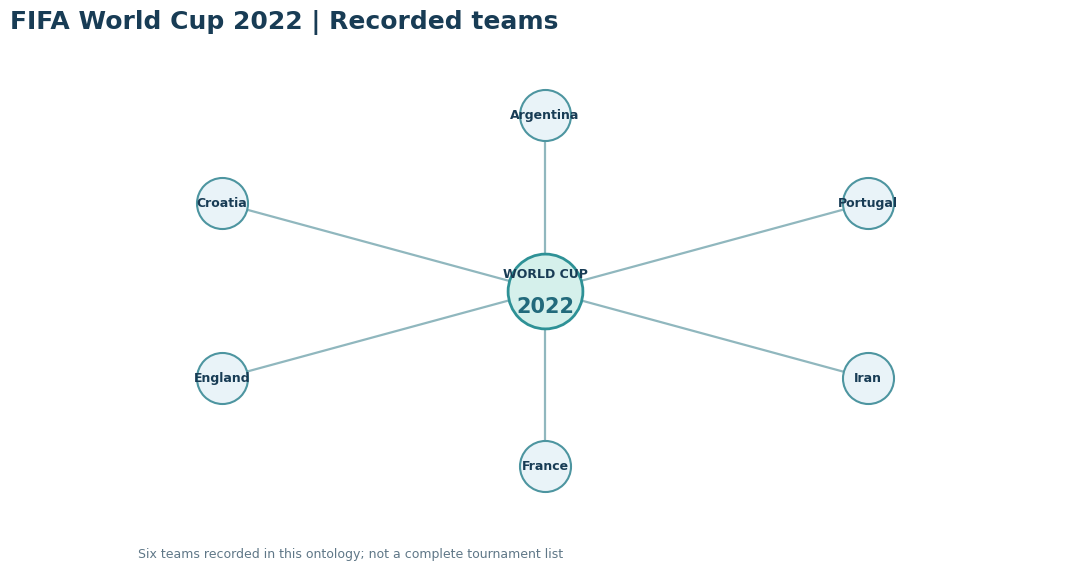

In [4]:
# 图中的队伍和连线直接来自本体的 competedIn 三元组。
competition = HS.FIFAWorldCup2022
teams = sorted({str(team).split("#")[-1] for team in graph.subjects(HS.competedIn, competition)})
assert len(teams) == 6
fig, ax = plt.subplots(figsize=(11, 5.8), facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.set_xlim(-1.65, 1.65); ax.set_ylim(-1.12, 1.12); ax.axis("off")
ax.scatter([0], [0], s=2900, color="#D5F0EB", edgecolors="#2E9196", linewidths=2, zorder=3)
ax.text(0, 0.06, "WORLD CUP", ha="center", color="#183C55", weight="bold", fontsize=9)
ax.text(0, -0.10, "2022", ha="center", color="#226A7B", fontsize=15, weight="bold")
for idx, team in enumerate(teams):
    angle = np.pi / 2 + 2*np.pi*idx / len(teams)
    x, y = 1.15*np.cos(angle), 0.80*np.sin(angle)
    ax.plot([0, x], [0, y], color="#90B7BE", linewidth=1.6, zorder=1)
    ax.scatter([x], [y], s=1350, color="#E9F3F8", edgecolors="#4D95A0", linewidths=1.5, zorder=2)
    name = team.replace("NationalTeam", "").replace("Team", "")
    ax.text(x, y, name, ha="center", va="center", color="#183C55", fontsize=9, weight="bold", zorder=4)
ax.set_title("FIFA World Cup 2022 | Recorded teams", loc="left", color="#183C55", fontsize=18, weight="bold", pad=12)
fig.text(.13,.03,"Six teams recorded in this ontology; not a complete tournament list", color="#5F7787", fontsize=9)
plt.tight_layout(rect=(0,.04,1,1)); plt.show()

## 5. Recorded teams per competition
The bars count distinct teams linked to each competition. A larger bar reflects more recorded examples, not the actual number of participating teams.

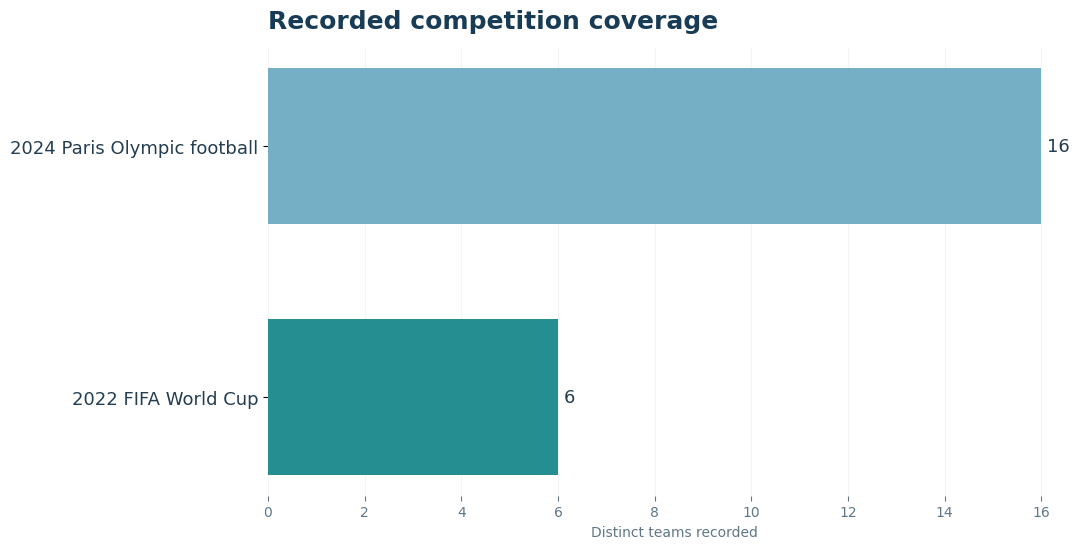

In [5]:
# 统计每项赛事中已经录入的不同队伍。
prefix = "PREFIX hs: <urn:hopfield:sports:domain#> "
team_counts = list(graph.query(prefix + "SELECT ?competition (COUNT(DISTINCT ?team) AS ?count) WHERE { ?team hs:competedIn ?competition } GROUP BY ?competition ORDER BY DESC(?count)"))
names = {"FIFAWorldCup2022": "2022 FIFA World Cup", "ParisOlympicFootball2024": "2024 Paris Olympic football"}
labels = [names.get(str(row[0]).split("#")[-1], str(row[0]).split("#")[-1]) for row in team_counts[:8]]
counts = [int(row[1]) for row in team_counts[:8]]
fig, ax = plt.subplots(figsize=(11,5.6),facecolor="#FFFFFF"); ax.set_facecolor("#FFFFFF")
ax.barh(range(len(labels)),counts,color=["#248E91" if "FIFA" in x else "#75AFC6" for x in labels],height=.62)
ax.set_yticks(range(len(labels)),labels=labels,color="#243D50",fontsize=13); ax.invert_yaxis()
ax.set_xlabel("Distinct teams recorded",color="#5F7787"); ax.tick_params(axis="x",colors="#5F7787")
for i,n in enumerate(counts): ax.text(n+.12,i,str(n),va="center",color="#243D50",fontsize=13)
for spine in ax.spines.values(): spine.set_visible(False)
ax.grid(axis="x",color="#D7E5EA",alpha=.35); ax.set_axisbelow(True)
ax.set_title("Recorded competition coverage",loc="left",color="#183C55",fontsize=18,weight="bold",pad=14)
plt.tight_layout(); plt.show()

## 6. Recorded membership by team
Membership records preserve athlete, team and time context. The chart counts distinct athletes linked through `TeamMembership`; missing teams or entries indicate missing records.

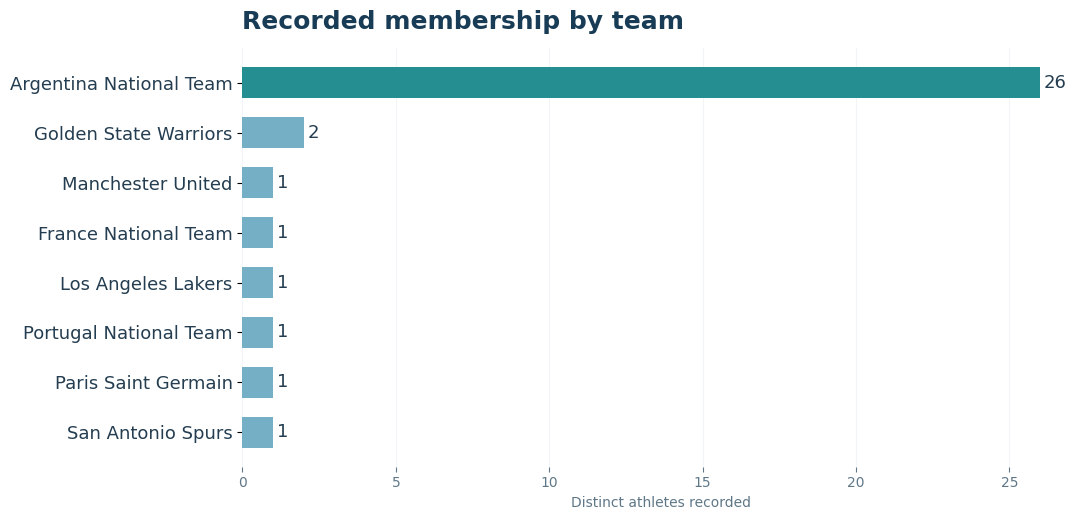

In [6]:
# 成员数以不同运动员计数，不将未录入解释为零。
membership_counts = list(graph.query(prefix + "SELECT ?team (COUNT(DISTINCT ?athlete) AS ?count) WHERE { ?membership a hs:TeamMembership ; hs:membershipTeam ?team ; hs:memberAthlete ?athlete } GROUP BY ?team ORDER BY DESC(?count)"))
labels = [re.sub(r"(?<=[a-z])(?=[A-Z])", " ", str(row[0]).split("#")[-1]) for row in membership_counts[:8]]
counts = [int(row[1]) for row in membership_counts[:8]]
fig, ax = plt.subplots(figsize=(11,5.3),facecolor="#FFFFFF"); ax.set_facecolor("#FFFFFF")
ax.barh(range(len(labels)),counts,color=["#248E91" if "Argentina" in x else "#75AFC6" for x in labels],height=.62)
ax.set_yticks(range(len(labels)),labels=labels,color="#243D50",fontsize=13); ax.invert_yaxis()
ax.set_xlabel("Distinct athletes recorded",color="#5F7787"); ax.tick_params(axis="x",colors="#5F7787")
for i,n in enumerate(counts): ax.text(n+.12,i,str(n),va="center",color="#243D50",fontsize=13)
for spine in ax.spines.values(): spine.set_visible(False)
ax.grid(axis="x",color="#D7E5EA",alpha=.35); ax.set_axisbelow(True)
ax.set_title("Recorded membership by team",loc="left",color="#183C55",fontsize=18,weight="bold",pad=14)
plt.tight_layout(); plt.show()

## 7. Interpretation and limitations
- The five query examples run locally with RDFLib against the final OWL file.
- The figures count recorded relations and do not cover all real-world sport.
- Missing information is not evidence that an event or relationship did not exist.
- The NLP demonstration is limited to a fixed entity and query template.